In [ ]:
import pandas as pd

df = pd.read_csv('/content/credit_risk_dataset.csv')

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (32581, 12)

First 5 Rows:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4



Column Names:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']


In [ ]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDataset Information:")
df.info()

Missing Values in Each Column:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

Total Missing Values:
4011

Duplicate Rows:
165

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_inte

In [ ]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print(df.isnull().sum().sum())

print(df.duplicated().sum())

df.info()

Missing Values in Each Column:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64
4011
165
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade    

In [ ]:
print("Statistical Summary:")
display(df.describe())

print("\nLoan Status Distribution:")
print(df["loan_status"].value_counts())

print("\nLoan Intent Distribution:")
print(df["loan_intent"].value_counts())

Statistical Summary:


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000



Loan Status Distribution:
loan_status
0    25473
1     7108
Name: count, dtype: int64

Loan Intent Distribution:
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64


In [ ]:
total_loans = len(df)

default_loans = (df["loan_status"] == 1).sum()

non_default_loans = (df["loan_status"] == 0).sum()

default_rate = (default_loans / total_loans) * 100

print("Total Loans:", total_loans)
print("Default Loans:", default_loans)
print("Non-Default Loans:", non_default_loans)
print("Default Rate:", round(default_rate, 2), "%")

Total Loans: 32581
Default Loans: 7108
Non-Default Loans: 25473
Default Rate: 21.82 %


In [ ]:
intent_analysis = df.groupby("loan_intent").agg(
    total_loans=("loan_status", "count"),
    default_loans=("loan_status", "sum")
)

intent_analysis["default_rate_percentage"] = (
    intent_analysis["default_loans"]
    / intent_analysis["total_loans"]
    * 100
).round(2)

intent_analysis = intent_analysis.sort_values(
    "default_rate_percentage",
    ascending=False
)

display(intent_analysis)

,total_loans,default_loans,default_rate_percentage
loan_intent,,,
DEBTCONSOLIDATION,5212,1490,28.59
MEDICAL,6071,1621,26.70
HOMEIMPROVEMENT,3605,941,26.10
PERSONAL,5521,1098,19.89
EDUCATION,6453,1111,17.22
VENTURE,5719,847,14.81


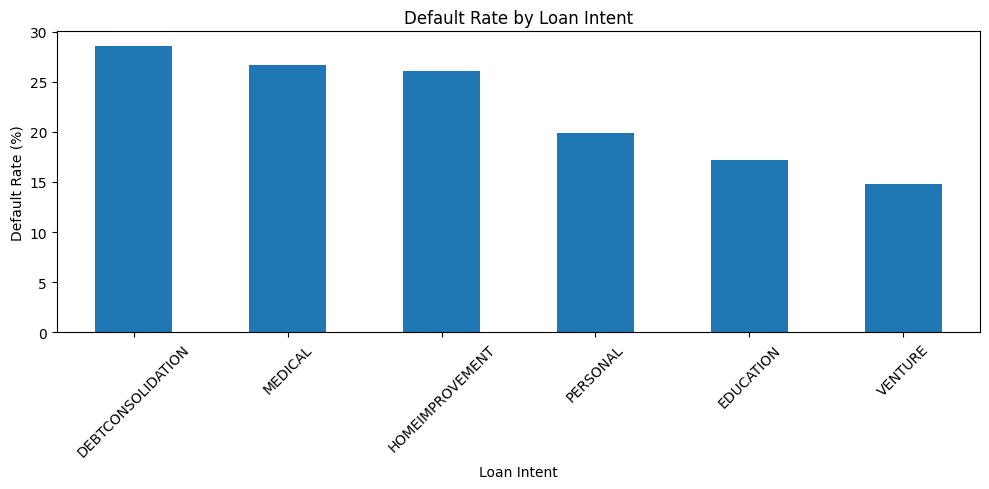

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

intent_analysis["default_rate_percentage"].plot(
    kind="bar"
)

plt.title("Default Rate by Loan Intent")
plt.xlabel("Loan Intent")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
home_analysis = df.groupby("person_home_ownership").agg(
    total_loans=("loan_status", "count"),
    default_loans=("loan_status", "sum")
)

home_analysis["default_rate_percentage"] = (
    home_analysis["default_loans"]
    / home_analysis["total_loans"]
    * 100
).round(2)

home_analysis = home_analysis.sort_values(
    "default_rate_percentage",
    ascending=False
)

display(home_analysis)

,total_loans,default_loans,default_rate_percentage
person_home_ownership,,,
RENT,16446,5192,31.57
OTHER,107,33,30.84
MORTGAGE,13444,1690,12.57
OWN,2584,193,7.47


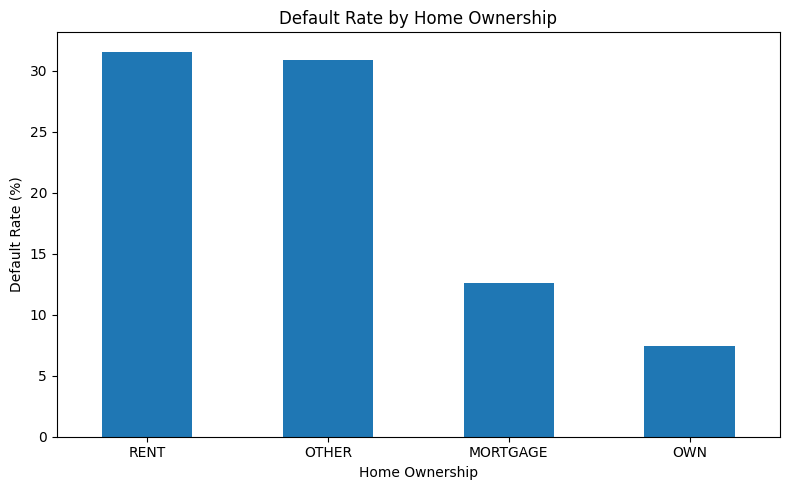

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

home_analysis["default_rate_percentage"].plot(kind="bar")

plt.title("Default Rate by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
grade_analysis = df.groupby("loan_grade").agg(
    total_loans=("loan_status", "count"),
    default_loans=("loan_status", "sum")
)

grade_analysis["default_rate_percentage"] = (
    grade_analysis["default_loans"]
    / grade_analysis["total_loans"]
    * 100
).round(2)

grade_analysis = grade_analysis.sort_values(
    "default_rate_percentage",
    ascending=False
)

display(grade_analysis)

,total_loans,default_loans,default_rate_percentage
loan_grade,,,
G,64,63,98.44
F,241,170,70.54
E,964,621,64.42
D,3626,2141,59.05
C,6458,1339,20.73
B,10451,1701,16.28
A,10777,1073,9.96


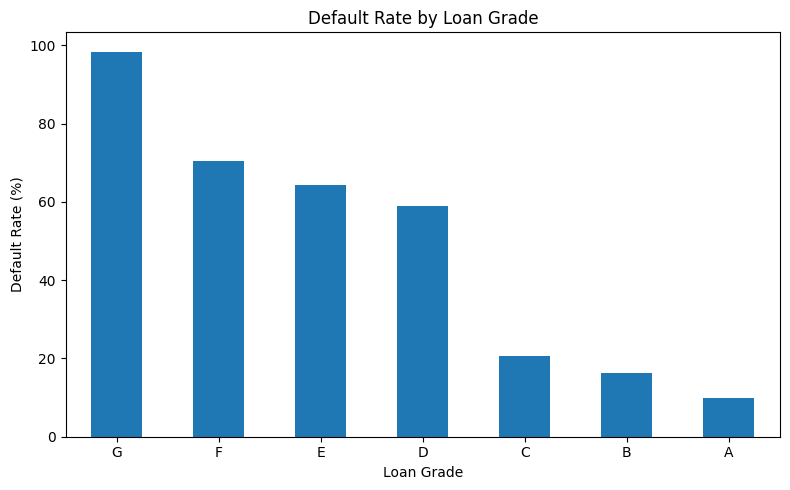

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

grade_analysis["default_rate_percentage"].plot(kind="bar")

plt.title("Default Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
df["risk_category"] = df["loan_percent_income"].apply(
    lambda x: "High Risk" if x >= 0.40
    else "Medium Risk" if x >= 0.20
    else "Low Risk"
)

risk_analysis = df.groupby("risk_category").agg(
    total_loans=("loan_status", "count"),
    default_loans=("loan_status", "sum")
)

risk_analysis["default_rate_percentage"] = (
    risk_analysis["default_loans"]
    / risk_analysis["total_loans"]
    * 100
).round(2)

display(risk_analysis)

,total_loans,default_loans,default_rate_percentage
risk_category,,,
High Risk,1335,983,73.63
Low Risk,21479,2879,13.40
Medium Risk,9767,3246,33.23


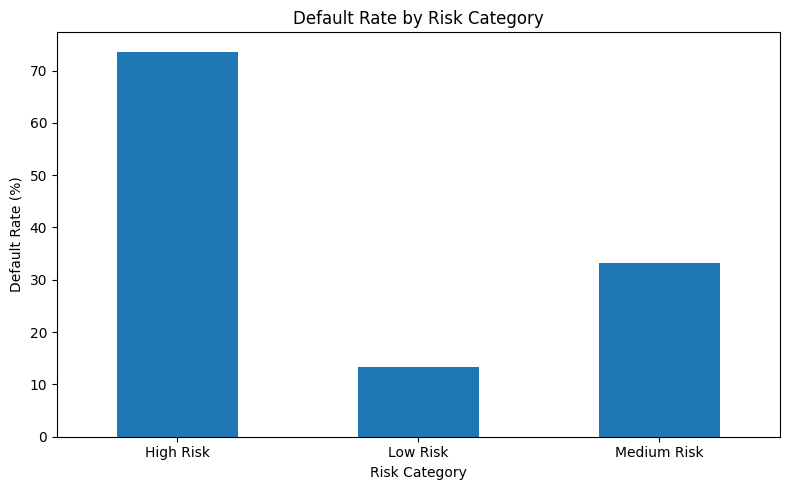

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

risk_analysis["default_rate_percentage"].plot(kind="bar")

plt.title("Default Rate by Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Save analysis results
intent_analysis.to_csv("loan_intent_analysis.csv")
home_analysis.to_csv("home_ownership_analysis.csv")
grade_analysis.to_csv("loan_grade_analysis.csv")
risk_analysis.to_csv("risk_category_analysis.csv")

print("All analysis files exported successfully!")

All analysis files exported successfully!
